# CNN — 2A, 2B, 2C

Your original CNN workflow is retained. Only the data shape and dataset loader change.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import models, layers, datasets

In [2]:
train = pd.read_csv("sign_mnist_train.csv")
test = pd.read_csv("sign_mnist_test.csv")

# Separate labels and images
y_train = train.iloc[:,0].values
x_train = train.iloc[:,1:].values

y_test = test.iloc[:,0].values
x_test = test.iloc[:,1:].values

# Normalize images
x_train = x_train.astype("float32")/255
x_test = x_test.astype("float32")/255

# Flatten images
x_train = x_train.reshape(-1,28,28,1) #(-1, 32 ,32 ,3) for CIFAR
x_test = x_test.reshape(-1,28,28,1)  #(-1, 32 ,32 ,3) for CIFAR


In [4]:
model = models.Sequential([
    layers.Input(shape=x_train.shape[1:]),
    layers.Conv2D(32,3,activation="relu",padding="same"),
    layers.MaxPooling2D(),
    layers.Conv2D(64,3,activation="relu",padding="same"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128,activation="relu"),
    layers.Dense(26,activation="softmax")
])
model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
history = model.fit(x_train,y_train,epochs=10,batch_size=64,validation_split=0.1)
print("Test loss, accuracy:",model.evaluate(x_test,y_test))


Epoch 1/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.6575 - loss: 1.1679 - val_accuracy: 0.9232 - val_loss: 0.2415
Epoch 2/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.9790 - loss: 0.0922 - val_accuracy: 0.9996 - val_loss: 0.0210
Epoch 3/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9995 - loss: 0.0139 - val_accuracy: 1.0000 - val_loss: 0.0063
Epoch 4/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 1.0000 - loss: 0.0040 - val_accuracy: 1.0000 - val_loss: 0.0027
Epoch 5/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 1.0000 - loss: 0.0020 - val_accuracy: 1.0000 - val_loss: 0.0015
Epoch 6/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 1.0000 - loss: 0.0011 - val_accuracy: 1.0000 - val_loss: 9.6960e-04
Epoch 7/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 1.0000 - loss: 7.1112e-04 - val_accuracy: 1.0000 - val_loss: 6.3898e-04
Epoch 8/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 1.0000 - loss: 4.795

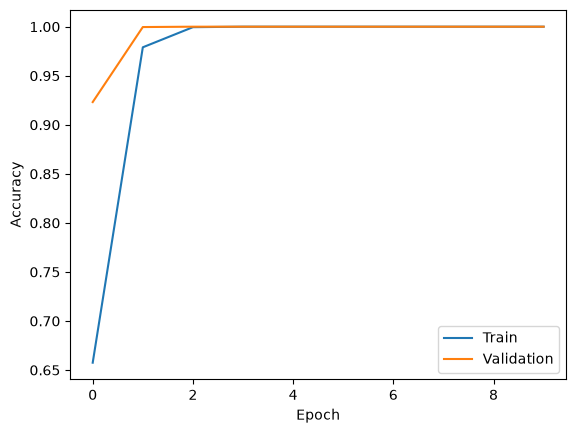

In [5]:
plt.plot(history.history["accuracy"],label="Train")
plt.plot(history.history["val_accuracy"],label="Validation")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.show()
